# Partial correction: subgroup evaluation
Probability ROC-AUC and empty-group checks are corrected. Outputs have been cleared. Rerun only after upstream temporal features, splits, and model predictions are corrected. This notebook has not been executed against the private data.


In [1]:
import numpy as np
from sklearn.metrics import roc_auc_score
def safe_roc_auc(y_true, y_probability):
    """AUC is undefined for empty or single-class subgroups."""
    if len(y_true) == 0 or len(np.unique(y_true)) < 2:
        return float("nan")
    return roc_auc_score(y_true, y_probability)


# **Loading The Files**

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
BASE_PATH = "/content/drive/MyDrive/Projects/Tennis/v1_1/datasets"


In [4]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(BASE_PATH).parent

train = pd.read_parquet(f"{BASE_PATH}/v1_1_train.parquet")
val = pd.read_parquet(f"{BASE_PATH}/v1_1_val.parquet")
test = pd.read_parquet(f"{BASE_PATH}/v1_1_test.parquet")

train_log = pd.read_parquet(f"{BASE_PATH}/v1_1_train_log.parquet")
val_log = pd.read_parquet(f"{BASE_PATH}/v1_1_val_log.parquet")
test_log = pd.read_parquet(f"{BASE_PATH}/v1_1_test_log.parquet")

# Match outcomes stay outside the model predictor datasets.
match_metadata = pd.read_csv(f"{BASE_PATH}/matches_v1_1_metadata.csv")
test_metadata = match_metadata.loc[match_metadata["split"].eq("test")].reset_index(drop=True)

for name, normal, logged in (("train", train, train_log),
                             ("val", val, val_log),
                             ("test", test, test_log)):
    if not normal.columns.equals(logged.columns):
        raise ValueError(f"{name}: logged and regular column schemas differ")
    if not normal.columns.equals(train.columns):
        raise ValueError(f"{name}: column schema differs from training")
if len(test_metadata) != len(test):
    raise ValueError("Test metadata does not align with the test parquet")


# **Separating Predictors and Labels**

In [5]:
import gc
target_cols = ['playerA_match_p', 'playerB_match_p']

X_train_log = train_log.drop(columns=target_cols)
y_trainA_log = train_log[target_cols[0]]
y_trainB_log = train_log[target_cols[1]]

X_val_log = val_log.drop(columns=target_cols)
y_valA_log = val_log[target_cols[0]]
y_valB_log = val_log[target_cols[1]]

del train_log, val_log
gc.collect()


0

In [6]:
import gc

X_train = train.drop(columns=target_cols)
y_trainA = train[target_cols[0]]
y_trainB = train[target_cols[1]]

X_val = val.drop(columns=target_cols)
y_valA = val[target_cols[0]]
y_valB = val[target_cols[1]]

del train, val
gc.collect()


0

In [7]:
import gc

test_winner = test_metadata["playerA_wins"].astype(int).reset_index(drop=True)
if not test_winner.isin([0, 1]).all():
    raise ValueError("Invalid match-outcome labels in test metadata")

X_test = test.drop(columns=target_cols)
y_testA = test[target_cols[0]]
y_testB = test[target_cols[1]]
X_test_log = test_log.drop(columns=target_cols)

# Test and log variants must remain aligned row for row.
assert len(test_winner) == len(X_test) == len(X_test_log)
assert X_train.columns.equals(X_val.columns) and X_train.columns.equals(X_test.columns)
assert X_train_log.columns.equals(X_val_log.columns) and X_train_log.columns.equals(X_test_log.columns)
assert "playerA_wins" not in X_test.columns

del test, test_log
gc.collect()


0

# **Ablation Study**

## Preparation

### Datasets

In [8]:
# Ablation refits on train + validation, without using test labels.
# Elastic Net's saved sklearn Pipeline fits its scaler during each ablated refit.
X_train_val = pd.concat([X_train, X_val], ignore_index=True)
y_train_valA = pd.concat([y_trainA, y_valA], ignore_index=True)
y_train_valB = pd.concat([y_trainB, y_valB], ignore_index=True)
X_train_val_log = pd.concat([X_train_log, X_val_log], ignore_index=True)


In [9]:
ablation_A_predictions = pd.DataFrame()
ablation_B_predictions = pd.DataFrame()

PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/ablation_study_A.csv"
PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/ablation_study_B.csv"

ablation_A_predictions.to_csv(PATH_A, index= False)
ablation_B_predictions.to_csv(PATH_B, index= False)


### Feature Groups

In [10]:
feature_groups = {
    "Ranking": ["playerA_rank_filled", "playerB_rank_filled", "playerA_is_unranked", "playerB_is_unranked", "playerA_rank_points_missing", 
                "playerB_rank_points_missing", "rank_diff", "rank_ratio", "playerA_rank_points", "playerB_rank_points", "rank_points_diff", "playerA_top10", 
                "playerB_top10", "playerA_top32", "playerB_top32", "playerA_top64", "playerB_top64", "playerA_top100", "playerB_top100"], 

    "Elo": ["playerA_elo", "playerB_elo", "elo_diff", "playerA_surface_elo", "playerB_surface_elo", "surface_elo_diff", 
            'playerA_blended_elo', 'playerB_blended_elo', 'blended_elo_diff', 'elo_ratio', 'playerA_elo_momentum', 'playerB_elo_momentum', 
            'playerA_elo_volatility', 'playerB_elo_volatility', 'blended_elo_ratio', 'surface_elo_ratio'], 

    "Form": ["playerA_last10_wins", 
             "playerB_last10_wins", "playerA_last10_matches", "playerB_last10_matches", "playerA_last10_pct", "playerB_last10_pct", 
             "playerA_last25_wins", "playerB_last25_wins", "playerA_last25_matches", "playerB_last25_matches", "playerA_last25_pct", 
             "playerB_last25_pct", "playerA_surface10_wins", "playerB_surface10_wins", "playerA_surface10_matches", 
             "playerB_surface10_matches", "playerA_surface10_pct", "playerB_surface10_pct", "playerA_surface25_wins", 
             "playerB_surface25_wins", "playerA_surface25_matches", "playerB_surface25_matches", "playerA_surface25_pct", 
             "playerB_surface25_pct", "playerA_52w_wins", "playerB_52w_wins", "playerA_52w_matches", "playerB_52w_matches", 
             "playerA_52w_pct", "playerB_52w_pct", "playerA_career_matches", "playerB_career_matches", "playerA_surface_career_matches", 
             "playerB_surface_career_matches", "playerA_last10_losses", "playerB_last10_losses", "playerA_last25_losses", 
             "playerB_last25_losses", "playerA_surface10_losses", "playerB_surface10_losses", "playerA_surface25_losses", 
             "playerB_surface25_losses", "playerA_52w_losses", "playerB_52w_losses"], 

    "Matchup": ["playerA_h2h_wins", "playerB_h2h_wins", "h2h_total", "h2h_diff", "playerA_surface_h2h_wins", "playerB_surface_h2h_wins", 
                "surface_h2h_total", "surface_h2h_diff", "playerA_last5_h2h_wins", "playerB_last5_h2h_wins", "last5_h2h_total", 
                "last5_h2h_diff", "playerA_top20_wins", "playerB_top20_wins", "playerA_top20_losses", "playerB_top20_losses", 
                "playerA_top20_win_pct", "playerB_top20_win_pct", "playerA_hand_wins", "playerB_hand_wins", "playerA_hand_losses", 
                "playerB_hand_losses", "playerA_hand_win_pct", "playerB_hand_win_pct", 'playerA_top20_total', 'playerB_top20_total', 
                'playerA_hand_total', 'playerB_hand_total'], 

    "Fatigue": [f"player{side}_{suffix}" for side in ("A", "B")
                for suffix in ("matches_30d", "wins_30d", "losses_30d",
                               "winpct_30d", "matches_60d",
                               "tournaments_5w", "tournaments_10w")],

    "Serve": ["playerA_ace_pct", "playerB_ace_pct", "playerA_df_pct", "playerB_df_pct", "playerA_1stIn_pct", "playerB_1stIn_pct", 
              "playerA_1stWon_pct", "playerB_1stWon_pct", "playerA_2ndWon_pct", "playerB_2ndWon_pct", "playerA_career_p", 
              "playerB_career_p", "playerA_serve_matches", "playerB_serve_matches", "playerA_matchup_p", "playerB_matchup_p", 
              "playerA_matchup_service_points", "playerB_matchup_service_points", "playerA_surface_p", "playerB_surface_p", 
              "playerA_surface_serve_matches", "playerB_surface_serve_matches"], 

    "Return": ["playerA_return_pct", "playerB_return_pct", "playerA_bp_convert_pct", "playerB_bp_convert_pct", "playerA_return_matches", 
               "playerB_return_matches"], 

    "Physical":  ['playerA_hand_A', 'playerA_hand_L', 'playerA_hand_R', 'playerA_hand_U', 'playerB_hand_A', 'playerB_hand_L', 
                  'playerB_hand_R','playerB_hand_U', "playerA_age", "playerB_age", "age_diff", "playerA_ht", "playerB_ht", "height_diff"],

    "Seed":  ["playerA_seeded", "playerB_seeded", "seed_diff", "seed_diff_missing"], 

    "Surface Specialization": ["playerA_win_rate_specialization", "playerB_win_rate_specialization", "playerA_elo_specialization", 
                               "playerB_elo_specialization", "playerA_serve_specialization", "playerB_serve_specialization"],

    "Experience": ["playerA_career_wins", "playerB_career_wins", "playerA_career_losses", "playerB_career_losses", "playerA_career_matches",
                    "playerA_career_pct", "playerB_career_matches", "playerA_surface_career_matches", "playerB_surface_career_matches",
                    "playerB_career_pct", "playerA_surface_career_wins", "playerB_surface_career_wins", "playerA_surface_career_losses", 
                    "playerB_surface_career_losses", "playerA_surface_career_pct", "playerB_surface_career_pct","playerA_level_wins", 
                    "playerB_level_wins", "playerA_level_losses", "playerB_level_losses", "playerA_level_win_pct", 
                   "playerA_tourney_matches", "playerB_tourney_matches", "playerA_level_matches", "playerB_level_matches", 
                   "playerB_level_win_pct"], 

    "Tournament Context": ["draw_size", "best_of", 'playerA_entry_ALT', 'playerA_entry_ITF', 'playerA_entry_LL', 
                           'playerA_entry_NONE', 'playerA_entry_OTHER', 'playerA_entry_PR', 'playerA_entry_Q', 'playerA_entry_SE', 
                           'playerA_entry_WC', 'playerB_entry_ALT', 'playerB_entry_ITF', 'playerB_entry_LL', 'playerB_entry_NONE', 
                           'playerB_entry_OTHER', 'playerB_entry_PR', 'playerB_entry_Q', 'playerB_entry_SE', 'playerB_entry_WC',
                           'round_BR', 'round_ER', 'round_F', 'round_Q1', 'round_Q2', 'round_Q3', 'round_QF', 'round_R128', 'round_R16', 
                           'round_R32', 'round_R64', 'round_RR', 'round_SF', 'tourney_level_A', 'tourney_level_C', 'tourney_level_D', 
                           'tourney_level_F', 'tourney_level_G', 'tourney_level_M', 'surface_Carpet', 'surface_Clay', 'surface_Grass', 
                           'surface_Hard',]
}

# Include new historical features and flags introduced by V1.1.
feature_groups["Experience"] += ["playerA_tourney_appearances", "playerB_tourney_appearances"]
feature_groups["Form"] += [f"player{side}_{window}_missing"
                           for side in ("A", "B")
                           for window in ("last10", "last25", "surface10", "surface25")]
feature_groups["Matchup"] += ["last5_h2h_missing"]
feature_groups["Seed"] += ["playerA_seed", "playerB_seed"]

# Remove related specializations too when ablating their source statistics.
feature_groups["Elo"] += ["playerA_elo_specialization", "playerB_elo_specialization"]
feature_groups["Serve"] += ["playerA_serve_specialization", "playerB_serve_specialization"]
feature_groups["Form"] += ["playerA_win_rate_specialization", "playerB_win_rate_specialization"]

# Include any new one-hot categories without relying on a fixed category list.
context_prefixes = ("surface_", "round_", "tourney_level_", "playerA_entry_", "playerB_entry_")
feature_groups["Tournament Context"] += [col for col in X_train.columns
                                         if col.startswith(context_prefixes)]

# Use actual exported columns and prevent an ineffective empty-group ablation.
for group, columns in feature_groups.items():
    selected = list(dict.fromkeys(c for c in columns if c in X_train.columns))
    if not selected:
        raise ValueError(f"Ablation group {group!r} has no matching features")
    feature_groups[group] = selected
    print(f"{group}: {len(selected)} columns")


Ranking: 19 columns
Elo: 18 columns
Form: 54 columns
Matchup: 29 columns
Fatigue: 14 columns
Serve: 24 columns
Return: 6 columns
Physical: 14 columns
Seed: 6 columns
Surface Specialization: 6 columns
Experience: 28 columns
Tournament Context: 47 columns


### Loading Models

In [11]:
!pip install catboost


In [12]:
import joblib
from google.colab import drive
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.linear_model import ElasticNet
from lightgbm import LGBMRegressor

drive.mount('/content/drive')
ENET_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/enet_final_playerA.pkl"
XGB_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/XGBoost_final_playerA.pkl"
LGB_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/lightGBM_final_playerA.pkl"
CAT_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/catBoost_final_playerA.pkl"

enet_A = joblib.load(ENET_PATH_A)
xgb_A = joblib.load(XGB_PATH_A)
lgbm_A = joblib.load(LGB_PATH_A)
cat_A = joblib.load(CAT_PATH_A)

from sklearn.pipeline import Pipeline
if not isinstance(enet_A, Pipeline):
    raise TypeError("V1.1 enet_final_playerA.pkl must be a fitted scaler+Elastic Net Pipeline")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
ENET_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/enet_final_playerB.pkl"
XGB_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/XGBoost_final_playerB.pkl"
LGB_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/lightGBM_final_playerB.pkl"
CAT_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/catBoost_final_playerB.pkl"

enet_B = joblib.load(ENET_PATH_B)
xgb_B = joblib.load(XGB_PATH_B)
lgbm_B = joblib.load(LGB_PATH_B)
cat_B = joblib.load(CAT_PATH_B)

if not isinstance(enet_B, Pipeline):
    raise TypeError("V1.1 enet_final_playerB.pkl must be a fitted scaler+Elastic Net Pipeline")


## Training Models & Making Predictions

### Without Removing Anything

In [14]:
RESULTS_PATH = PROJECT_DIR / "v1_1_results.joblib"
anal_data = joblib.load(RESULTS_PATH)
if len(anal_data) != len(test_winner):
    raise ValueError("Saved V1.1 prediction rows do not match test metadata")
if "playerA_wins" in anal_data and not np.array_equal(
        anal_data["playerA_wins"].to_numpy(), test_winner.to_numpy()):
    raise ValueError("Saved predictions and test metadata have different outcomes/order")

ablation_A_predictions = pd.DataFrame({"nothing": anal_data["p"].to_numpy()})
ablation_B_predictions = pd.DataFrame({"nothing": anal_data["q"].to_numpy()})

PATH_A = str(PROJECT_DIR / "ablation_study_A.csv")
PATH_B = str(PROJECT_DIR / "ablation_study_B.csv")

ablation_A_predictions.to_csv(PATH_A, index=False)
ablation_B_predictions.to_csv(PATH_B, index=False)

# Ablation also uses the full model's fixed validation inverse-MAE weights.
from sklearn.metrics import mean_absolute_error
val_preds = joblib.load(PROJECT_DIR / "v1_1_individual_model_prediction_dataframe.joblib")
ensemble_keys = ("enet", "lightgbm", "xgboost", "catboost")
maes = np.array([mean_absolute_error(val_preds["y_true"], val_preds[k]) for k in ensemble_keys])
inverse_weights = 1.0 / np.maximum(maes, 1e-12)
inverse_weights /= inverse_weights.sum()


### Removing Feature Groups

In [15]:
from sklearn.base import clone
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import numpy as np


def ablation(feature_group):
    X_train_val_log_dropped = X_train_val_log.drop(columns=feature_groups[feature_group])
    X_train_val_dropped = X_train_val.drop(columns=feature_groups[feature_group])

    X_test_dropped = X_test.drop(columns=feature_groups[feature_group])
    X_test_log_dropped = X_test_log.drop(columns=feature_groups[feature_group])


    # Fetch parameters as dictionaries
    xgb_A_params = xgb_A.get_params()
    lgbm_A_params = lgbm_A.get_params()
    cat_A_params = cat_A.get_params()

    xgb_B_params = xgb_B.get_params()
    lgbm_B_params = lgbm_B.get_params()
    cat_B_params = cat_B.get_params()

    # Overwrite the GPU device settings to CPU
    xgb_A_params['device'] = 'cpu'
    xgb_B_params['device'] = 'cpu'

    for params in [lgbm_A_params, lgbm_B_params]:
        if 'device' in params: params['device'] = 'cpu'
        if 'device_type' in params: params['device_type'] = 'cpu'

    cat_A_params['task_type'] = 'CPU'
    cat_B_params['task_type'] = 'CPU'

    # Instantiate the new models safely
    enet_A_dropped = clone(enet_A)
    xgb_A_dropped = XGBRegressor(**xgb_A_params)
    lgbm_A_dropped = LGBMRegressor(**lgbm_A_params)
    cat_A_dropped = CatBoostRegressor(**cat_A_params)

    enet_B_dropped = clone(enet_B)
    xgb_B_dropped = XGBRegressor(**xgb_B_params)
    lgbm_B_dropped = LGBMRegressor(**lgbm_B_params)
    cat_B_dropped = CatBoostRegressor(**cat_B_params)
    
    

    enet_A_dropped.fit(X_train_val_log_dropped, y_train_valA)
    xgb_A_dropped.fit(X_train_val_dropped, y_train_valA)
    lgbm_A_dropped.fit(X_train_val_dropped, y_train_valA)
    cat_A_dropped.fit(X_train_val_dropped, y_train_valA)

    enet_B_dropped.fit(X_train_val_log_dropped, y_train_valB)
    xgb_B_dropped.fit(X_train_val_dropped, y_train_valB)
    lgbm_B_dropped.fit(X_train_val_dropped, y_train_valB)
    cat_B_dropped.fit(X_train_val_dropped, y_train_valB)


    enetA_preds = np.clip(enet_A_dropped.predict(X_test_log_dropped), 0, 1)
    xgbA_preds = np.clip(xgb_A_dropped.predict(X_test_dropped), 0, 1)
    lgbmA_preds = np.clip(lgbm_A_dropped.predict(X_test_dropped), 0, 1)
    cat_A_preds = np.clip(cat_A_dropped.predict(X_test_dropped), 0, 1)

    enetB_preds = np.clip(enet_B_dropped.predict(X_test_log_dropped), 0, 1)
    xgbB_preds = np.clip(xgb_B_dropped.predict(X_test_dropped), 0, 1)
    lgbmB_preds = np.clip(lgbm_B_dropped.predict(X_test_dropped), 0, 1)
    cat_B_preds = np.clip(cat_B_dropped.predict(X_test_dropped), 0, 1)

    ensembleA_preds = np.average(np.stack([enetA_preds, lgbmA_preds, xgbA_preds, cat_A_preds]),
                                  axis=0, weights=inverse_weights)
    ensembleB_preds = np.average(np.stack([enetB_preds, lgbmB_preds, xgbB_preds, cat_B_preds]),
                                  axis=0, weights=inverse_weights)

    return ensembleA_preds, ensembleB_preds


In [16]:
ablation_A_predictions = pd.read_csv("/content/drive/MyDrive/Projects/Tennis/v1_1/ablation_study_A.csv")
ablation_B_predictions = pd.read_csv("/content/drive/MyDrive/Projects/Tennis/v1_1/ablation_study_B.csv")

for i in feature_groups:
    ensembleA_preds, ensembleB_preds = ablation(i)

    ablation_A_predictions[f"{i}"] = ensembleA_preds
    ablation_B_predictions[f"{i}"] = ensembleB_preds
    print(f"{i} drop done.")


ablation_A_predictions.to_csv("/content/drive/MyDrive/Projects/Tennis/v1_1/ablation_study_A.csv", index= False)
ablation_B_predictions.to_csv("/content/drive/MyDrive/Projects/Tennis/v1_1/ablation_study_B.csv", index= False)    


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.444453 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 27402
[LightGBM] [Info] Number of data points in the train set: 207741, number of used features: 227
[LightGBM] [Info] Start training from score 0.620771
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

## Computing MAE

In [17]:
import pandas as pd
from sklearn.metrics import mean_absolute_error

pred_A = pd.read_csv("/content/drive/MyDrive/Projects/Tennis/v1_1/ablation_study_A.csv")
pred_B = pd.read_csv("/content/drive/MyDrive/Projects/Tennis/v1_1/ablation_study_B.csv")

results = []

for col in pred_A.columns:

    mae_A = mean_absolute_error(y_testA, pred_A[col])
    mae_B = mean_absolute_error(y_testB, pred_B[col])

    results.append({
        "Feature Group Removed": col,
        "Player A MAE": mae_A,
        "Player B MAE": mae_B,
        "Average MAE": (mae_A + mae_B) / 2
    })

results = pd.DataFrame(results)


In [18]:
baseline = results.loc[
    results["Feature Group Removed"] == "nothing",
    "Average MAE"
].iloc[0]

results["Delta MAE"] = results["Average MAE"] - baseline

results = results.sort_values("Delta MAE", ascending=False)


In [19]:
results["% Increase"] = (
    results["Delta MAE"] / baseline
) * 100

results = results.sort_values("% Increase", ascending=False)


In [20]:
results.to_csv( "/content/drive/MyDrive/Projects/Tennis/v1_1/ablation_results.csv", index=False)


In [21]:
print(results)


     Feature Group Removed  Player A MAE  Player B MAE  Average MAE  \
2                      Elo      0.068935      0.068329     0.068632   
6                    Serve      0.068864      0.068309     0.068587   
7                   Return      0.068345      0.067806     0.068076   
3                     Form      0.068239      0.067698     0.067968   
5                  Fatigue      0.068243      0.067688     0.067966   
11              Experience      0.068224      0.067641     0.067933   
4                  Matchup      0.068188      0.067601     0.067894   
10  Surface Specialization      0.068170      0.067602     0.067886   
9                     Seed      0.068165      0.067597     0.067881   
0                  nothing      0.068148      0.067586     0.067867   
12      Tournament Context      0.068131      0.067578     0.067855   
8                 Physical      0.068098      0.067570     0.067834   
1                  Ranking      0.068049      0.067506     0.067778   

    D

## Plots

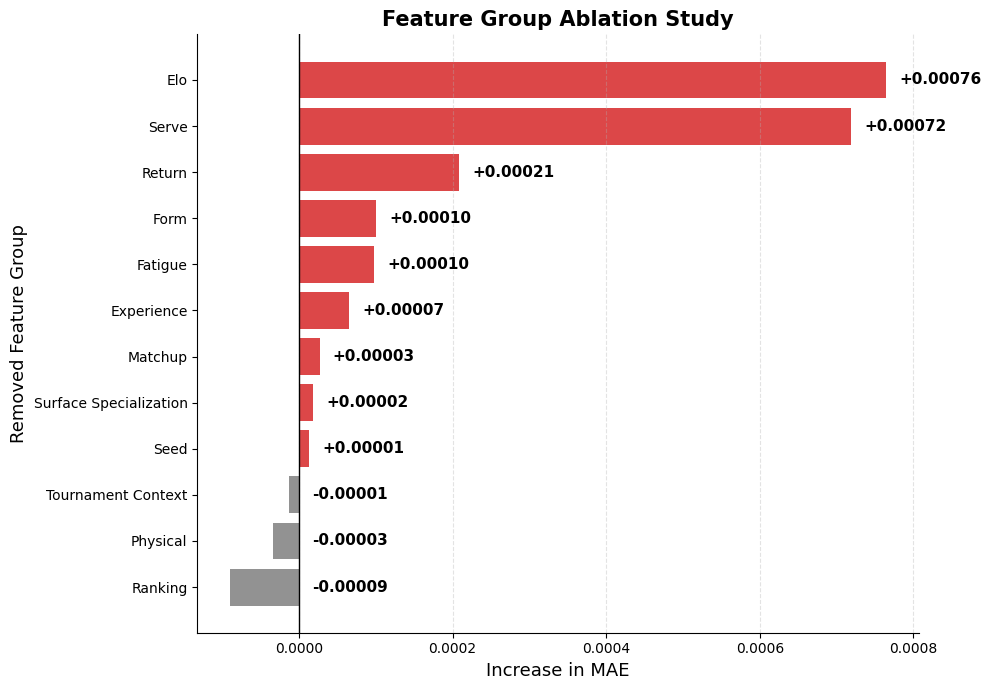

In [22]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = results[results["Feature Group Removed"] != "nothing"].copy()

# Sort by effect size (largest first)
plot_df = plot_df.sort_values("Delta MAE", ascending=False)

values = plot_df["Delta MAE"].values
labels = plot_df["Feature Group Removed"].values

# Colors
colors = ["tab:red" if x > 0 else "tab:gray" for x in values]

fig, ax = plt.subplots(figsize=(10,7))

bars = ax.barh(
    labels,
    values,
    color=colors,
    alpha=0.85
)

# Zero reference line
ax.axvline(0, color='black', linewidth=1)

# Light grid
ax.grid(axis='x', linestyle='--', alpha=0.35)

# Remove unnecessary borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Largest at top
ax.invert_yaxis()

# Axis labels
ax.set_xlabel("Increase in MAE", fontsize=13)
ax.set_ylabel("Removed Feature Group", fontsize=13)
ax.set_title("Feature Group Ablation Study", fontsize=15, weight='bold')

# Dynamic annotation placement
x_range = max(values) - min(values)
offset = x_range * 0.02

for bar, value in zip(bars, values):

    y = bar.get_y() + bar.get_height()/2

    if value >= 0:
        # Positive bars
        ax.text(
            value + offset,
            y,
            f"+{value:.5f}",
            va='center',
            ha='left',
            fontsize=11,
            fontweight='bold'
        )

    else:
        # Always place negative labels just to the right of zero
        ax.text(
            offset,
            y,
            f"{value:.5f}",
            va='center',
            ha='left',
            fontsize=11,
            fontweight='bold'
        )

plt.tight_layout()

# Uncomment when making thesis figures
# plt.savefig("ablation_study.png", dpi=300, bbox_inches="tight")

plt.show()


# **Error Analysis**

## Preparing Data

In [23]:
import pandas as pd
import joblib

predictions_df = joblib.load(RESULTS_PATH).reset_index(drop=True)
if len(predictions_df) != len(test_winner):
    raise ValueError("Saved prediction rows do not match test metadata")
if "playerA_wins" in predictions_df:
    if not np.array_equal(predictions_df["playerA_wins"].to_numpy(), test_winner.to_numpy()):
        raise ValueError("Prediction outcomes differ from test metadata")
else:
    predictions_df["playerA_wins"] = test_winner.to_numpy()
if not predictions_df["match_win_probA"].between(0, 1).all():
    raise ValueError("Invalid V1.1 match-win probabilities")
predictions_df.describe()


,p,q,best_of,playerA_wins,set_win_probA,deciding_set_win_probA,match_win_probA
count,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,5.166600e+04
mean,0.604602,0.605846,3.030968,0.496032,0.496739,0.496737,4.961991e-01
std,0.056467,0.055691,0.246938,0.499989,0.250457,0.250520,3.096282e-01
min,0.382544,0.386814,3.000000,0.000000,0.000334,0.000334,3.353257e-07
25%,0.570807,0.572442,3.000000,0.000000,0.309927,0.309860,2.277911e-01
50%,0.608655,0.609033,3.000000,0.000000,0.496412,0.496412,4.945993e-01
75%,0.642637,0.643746,3.000000,1.000000,0.683270,0.683383,7.635086e-01
max,0.788402,0.787955,5.000000,1.000000,0.999073,0.999073,9.999997e-01


In [24]:
#winner as predicted by model
predictions_df['playerA_wins_prediction'] = (predictions_df['match_win_probA'] >=0.5).astype('int')
predictions_df.describe()


,p,q,best_of,playerA_wins,set_win_probA,deciding_set_win_probA,match_win_probA,playerA_wins_prediction
count,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,5.166600e+04,51666.000000
mean,0.604602,0.605846,3.030968,0.496032,0.496739,0.496737,4.961991e-01,0.495181
std,0.056467,0.055691,0.246938,0.499989,0.250457,0.250520,3.096282e-01,0.499982
min,0.382544,0.386814,3.000000,0.000000,0.000334,0.000334,3.353257e-07,0.000000
25%,0.570807,0.572442,3.000000,0.000000,0.309927,0.309860,2.277911e-01,0.000000
50%,0.608655,0.609033,3.000000,0.000000,0.496412,0.496412,4.945993e-01,0.000000
75%,0.642637,0.643746,3.000000,1.000000,0.683270,0.683383,7.635086e-01,1.000000
max,0.788402,0.787955,5.000000,1.000000,0.999073,0.999073,9.999997e-01,1.000000


## Surface

### Preparation and Data Collection

In [25]:
import numpy as np
import pandas as pd

X_test_surface = X_test.copy()
surface_cols = [c for c in X_test_surface.columns if c.startswith("surface_")]

X_test_surface['surface'] = X_test_surface[surface_cols].idxmax(axis= 1).str.replace("surface_", "", regex=False)

X_test_surface.loc[X_test_surface[surface_cols].sum(axis=1).eq(0), "surface"] = pd.NA
X_test_surface[["surface"]].sample(min(10, len(X_test_surface)))


,surface
5414,elo_diff
7013,elo_diff
8398,elo_diff
47969,h2h_total
25475,h2h_total
6750,elo_diff
7971,Hard
38436,elo_diff
40393,Hard
49910,elo_diff


In [26]:
import pandas as pd

X_train_val = pd.concat([X_train, X_val], axis= 0)
surface_cols = ['surface_Carpet', 'surface_Clay', 'surface_Grass', 'surface_Hard']

X_train_val['surface'] = X_train_val[surface_cols].idxmax(axis= 1).str.replace("surface_", "", regex=False)

print(X_train_val['surface'].value_counts(dropna= False))


surface
Hard      105093
Clay       82409
Grass      13503
Carpet      6736
Name: count, dtype: int64


### Evaluating Metrics

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

surface_results = list()

for surface in sorted(X_test_surface['surface'].dropna().unique()):
    idx = X_test_surface["surface"]==surface

    y_true = predictions_df['playerA_wins'][idx]
    y_pred = predictions_df['playerA_wins_prediction'][idx]
    y_prob = predictions_df['match_win_probA'][idx]

    surface_results.append({
        "Surface": surface, 
        "Matches": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred), 
        "Precision": precision_score(y_true, y_pred, zero_division=0), 
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0), 
        "ROC-AUC": safe_roc_auc(y_true, y_prob)
        })
    
surface_results = pd.DataFrame(surface_results)

surface_results = surface_results.sort_values("Accuracy", ascending= False)
surface_results


,Surface,Matches,Accuracy,Precision,Recall,F1,ROC-AUC
1,Clay,8357,0.703602,0.594354,0.292933,0.392445,0.711662
3,Hard,11487,0.693305,0.610989,0.283168,0.386985,0.710996
4,elo_diff,25600,0.687344,0.703414,0.902264,0.790526,0.705944
6,h2h_total,5523,0.673728,0.584488,0.219335,0.318972,0.673658
0,Carpet,107,0.644860,0.575758,0.441860,0.500000,0.731831
2,Grass,418,0.636364,0.585106,0.327381,0.419847,0.692310
5,elo_ratio,174,0.597701,0.632653,0.645833,0.639175,0.637286


In [28]:
#formatted table
surface_table = surface_results.copy()

surface_table["Accuracy"] *= 100
surface_table["Precision"] *= 100
surface_table["Recall"] *= 100
surface_table["F1"] *= 100
surface_table["ROC-AUC"] *= 100

surface_table = surface_table.round(2)

surface_table


,Surface,Matches,Accuracy,Precision,Recall,F1,ROC-AUC
1,Clay,8357,70.36,59.44,29.29,39.24,71.17
3,Hard,11487,69.33,61.10,28.32,38.70,71.10
4,elo_diff,25600,68.73,70.34,90.23,79.05,70.59
6,h2h_total,5523,67.37,58.45,21.93,31.90,67.37
0,Carpet,107,64.49,57.58,44.19,50.00,73.18
2,Grass,418,63.64,58.51,32.74,41.98,69.23
5,elo_ratio,174,59.77,63.27,64.58,63.92,63.73


In [29]:
# Error rate
surface_table["Error Rate (%)"] = (100 - surface_table["Accuracy"])

surface_table


,Surface,Matches,Accuracy,Precision,Recall,F1,ROC-AUC,Error Rate (%)
1,Clay,8357,70.36,59.44,29.29,39.24,71.17,29.64
3,Hard,11487,69.33,61.10,28.32,38.70,71.10,30.67
4,elo_diff,25600,68.73,70.34,90.23,79.05,70.59,31.27
6,h2h_total,5523,67.37,58.45,21.93,31.90,67.37,32.63
0,Carpet,107,64.49,57.58,44.19,50.00,73.18,35.51
2,Grass,418,63.64,58.51,32.74,41.98,69.23,36.36
5,elo_ratio,174,59.77,63.27,64.58,63.92,63.73,40.23


In [30]:
overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100

surface_table["Difference in Accuracy"] = (surface_table["Accuracy"] - overall_accuracy).round(2)
surface_table


,Surface,Matches,Accuracy,Precision,Recall,F1,ROC-AUC,Error Rate (%),Difference in Accuracy
1,Clay,8357,70.36,59.44,29.29,39.24,71.17,29.64,1.46
3,Hard,11487,69.33,61.10,28.32,38.70,71.10,30.67,0.43
4,elo_diff,25600,68.73,70.34,90.23,79.05,70.59,31.27,-0.17
6,h2h_total,5523,67.37,58.45,21.93,31.90,67.37,32.63,-1.53
0,Carpet,107,64.49,57.58,44.19,50.00,73.18,35.51,-4.41
2,Grass,418,63.64,58.51,32.74,41.98,69.23,36.36,-5.26
5,elo_ratio,174,59.77,63.27,64.58,63.92,63.73,40.23,-9.13


### Plots

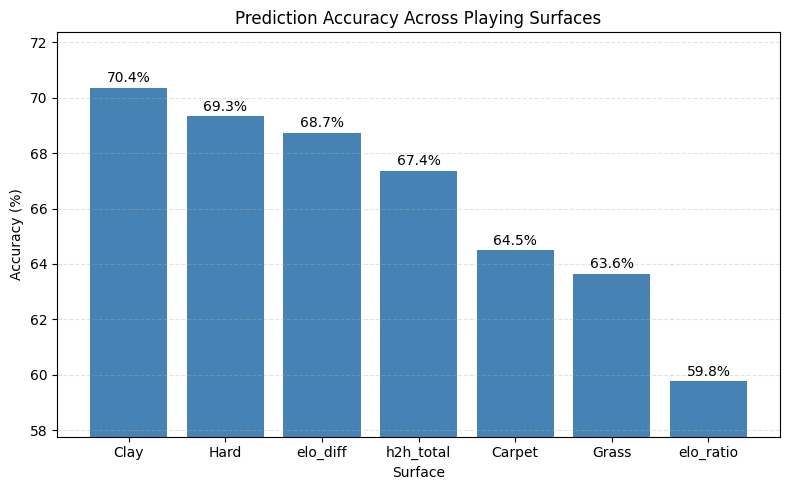

In [31]:
import matplotlib.pyplot as plt

plot_df = surface_table.sort_values("Accuracy", ascending=False)

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(plot_df["Surface"], plot_df["Accuracy"], color="steelblue")

ax.set_ylim(plot_df["Accuracy"].min()-2, plot_df["Accuracy"].max()+2)

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Surface")

ax.set_title("Prediction Accuracy Across Playing Surfaces")

ax.grid(axis="y", linestyle="--", alpha=0.35)

for bar, value in zip(bars, plot_df["Accuracy"]):
    ax.text(bar.get_x()+bar.get_width()/2, value+0.2, f"{value:.1f}%", ha="center", fontsize=10)

plt.tight_layout()
plt.show()


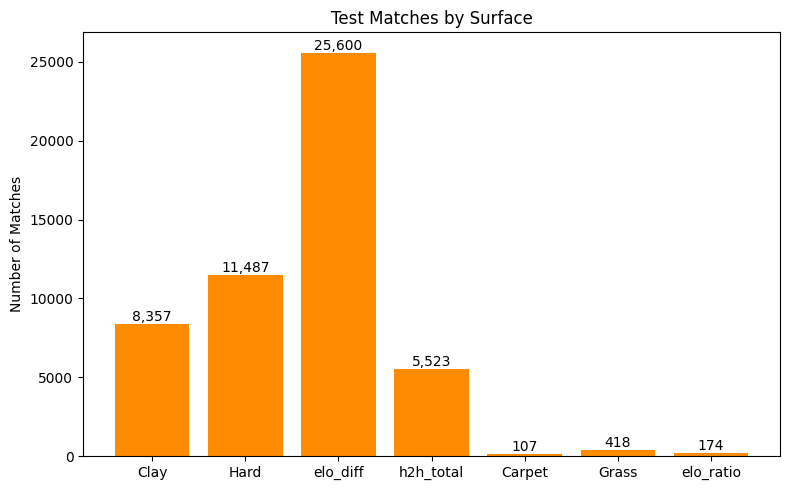

In [32]:
fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(surface_table["Surface"], surface_table["Matches"], color="darkorange")

ax.set_ylabel("Number of Matches")

ax.set_title("Test Matches by Surface")

for bar, value in zip(bars, surface_table["Matches"]):
    ax.text(bar.get_x()+bar.get_width()/2, value, f"{value:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()


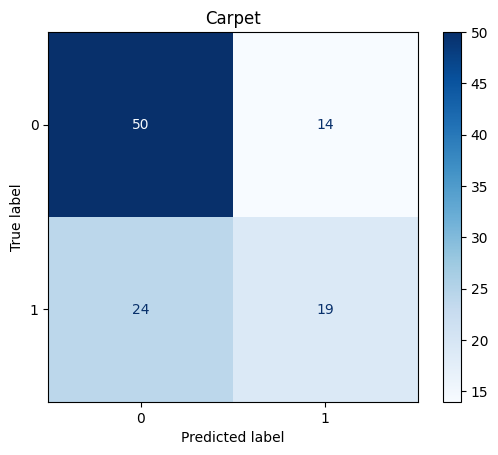

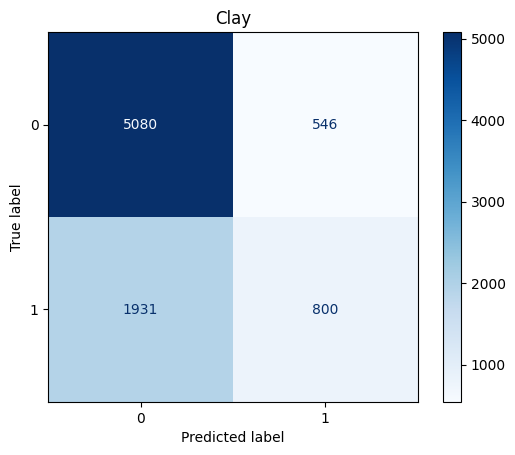

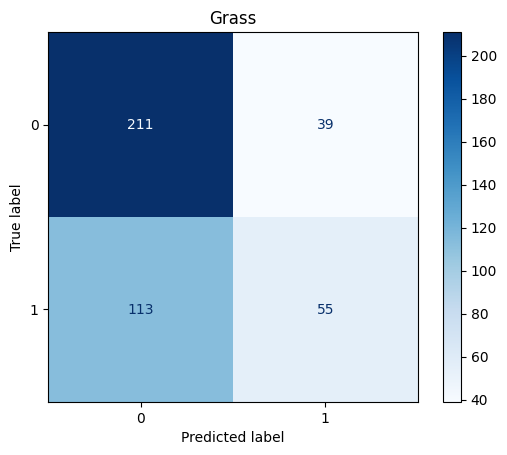

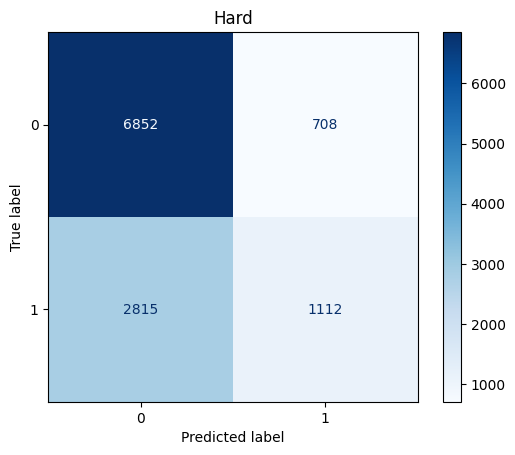

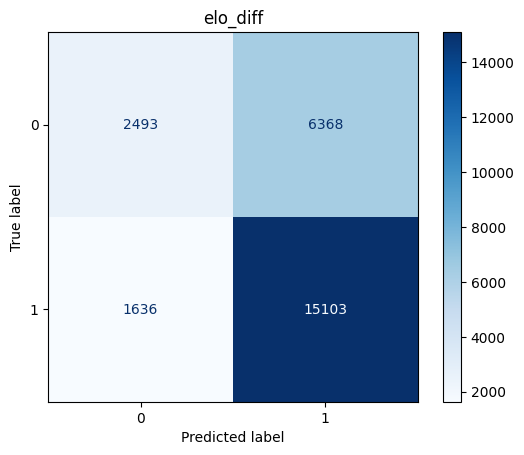

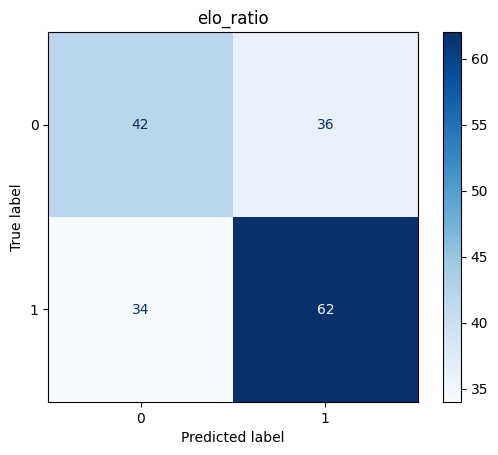

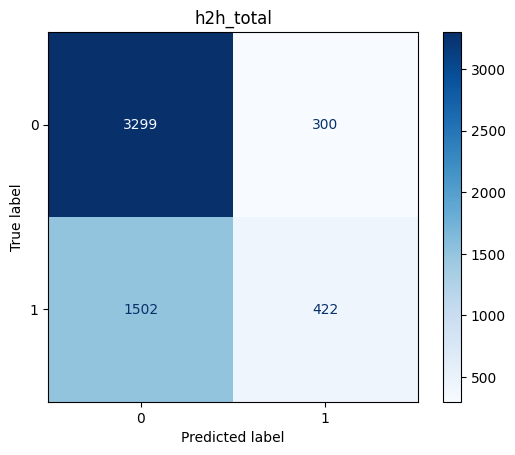

In [33]:
from sklearn.metrics import ConfusionMatrixDisplay

for surface in sorted(X_test_surface["surface"].dropna().unique()):
    idx = X_test_surface["surface"] == surface

    ConfusionMatrixDisplay.from_predictions(
        predictions_df['playerA_wins'][idx],
        predictions_df['playerA_wins_prediction'][idx],
        cmap="Blues"
    )

    plt.title(surface)
    plt.show()


## Elo 

### Preparation and Data Collection

In [34]:
X_test_elo = X_test.copy()

elo_features = ["playerA_elo", "playerB_elo", "elo_diff", "playerA_surface_elo", "playerB_surface_elo", "surface_elo_diff", 
            'playerA_blended_elo', 'playerB_blended_elo', 'blended_elo_diff', 'elo_ratio', 'playerA_elo_momentum', 'playerB_elo_momentum', 
            'playerA_elo_volatility', 'playerB_elo_volatility', 'blended_elo_ratio', 'surface_elo_ratio']

X_test_elo[elo_features].describe()


,playerA_elo,playerB_elo,elo_diff,playerA_surface_elo,playerB_surface_elo,surface_elo_diff,playerA_blended_elo,playerB_blended_elo,blended_elo_diff,elo_ratio,playerA_elo_momentum,playerB_elo_momentum,playerA_elo_volatility,playerB_elo_volatility,blended_elo_ratio,surface_elo_ratio
count,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000,51666.000000
mean,1712.869019,1713.364746,-0.495939,1652.078247,1652.532349,-0.454221,1670.315308,1670.781982,-0.466737,1.004336,4.710848,4.925275,16.878977,16.934288,1.003588,1.003567
std,218.671997,219.235153,163.672226,172.682953,173.257248,145.712921,184.529877,185.132736,147.129440,0.096450,36.198799,36.204906,11.418701,11.442281,0.087999,0.087731
min,1232.511841,1239.914307,-804.550598,1250.229126,1250.229126,-788.783936,1256.144165,1256.144165,-755.603577,0.639072,-107.531792,-107.531792,0.000000,0.000000,0.686930,0.659471
25%,1523.748932,1523.042999,-105.368357,1501.086151,1500.691650,-91.684504,1509.407349,1508.590271,-93.998934,0.940215,-19.709097,-19.607245,9.964867,9.959076,0.945179,0.945946
50%,1688.896118,1688.195129,-0.266050,1633.358887,1633.788086,-0.170917,1650.461365,1650.321655,-0.131561,0.999843,0.000000,0.000000,14.831819,14.851418,0.999917,0.999890
75%,1848.813965,1849.549072,104.293404,1761.851440,1762.503418,90.692810,1787.524902,1787.748932,92.364141,1.062876,23.769436,24.066504,21.645451,21.717752,1.057382,1.056695
max,2696.987549,2696.987549,890.586365,2511.952148,2511.952148,827.145325,2555.121338,2555.121338,815.289001,1.520988,230.551712,230.551712,104.286720,104.286720,1.521308,1.533572


In [35]:
import numpy as np
X_train_val = pd.concat([X_train, X_val], axis= 0)

X_train_val['elo_diff'] = X_train_val['elo_diff'].abs()

elo_bins = [0, 25, 50, 100, 200, np.inf]
elo_labels = ["0-25", "25-50", '50-100', '100-200', '>200']
X_train_val['elo_bin'] = pd.cut(X_train_val['elo_diff'], bins= elo_bins, labels= elo_labels, include_lowest= True)

X_train_val['elo_bin'].value_counts()


,count
elo_bin,
100-200,61755
>200,50149
50-100,45088
0-25,26059
25-50,24690


In [36]:
elo_bins = [0, 25, 50, 100, 200, np.inf]
elo_labels = ["0-25", "25-50", '50-100', '100-200', '>200']
X_train_val['surface_elo_diff'] = X_train_val['surface_elo_diff'].abs()
X_train_val['surface_elo_bin'] = pd.cut(X_train_val['surface_elo_diff'], bins= elo_bins, labels= elo_labels, include_lowest= True)

X_train_val['surface_elo_bin'].value_counts()


,count
surface_elo_bin,
100-200,62828
50-100,46858
>200,43655
0-25,27851
25-50,26549


### Evaluating Metrics

In [37]:
from sklearn.metrics import accuracy_score, roc_auc_score
import numpy as np

elo_bins = [0, 25, 50, 100, 200, np.inf]
elo_labels = ["0-25", "25-50", '50-100', '100-200', '>200']

X_test_elo['elo_diff'] = X_test_elo['elo_diff'].abs()

X_test_elo['elo_bin'] = pd.cut(X_test_elo['elo_diff'], bins= elo_bins, labels= elo_labels, include_lowest= True)

elo_results = list()

for group in elo_labels:
    idx = X_test_elo['elo_bin']==group

    if idx.sum()==0:
        continue

    elo_results.append({
        "Elo Difference": group, 
        "Matches": idx.sum(),
        "Accuracy": accuracy_score(predictions_df['playerA_wins'][idx], predictions_df['playerA_wins_prediction'][idx]),
        "ROC-AUC": safe_roc_auc(predictions_df['playerA_wins'][idx], predictions_df['match_win_probA'][idx])

    })

elo_results = pd.DataFrame(elo_results)


overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100
elo_results["Difference in Accuracy"] = (elo_results["Accuracy"]*100 - overall_accuracy).round(2)

elo_results["Error Rate (%)"] = ((1 - elo_results["Accuracy"])*100).round(2)
elo_results["Accuracy"] = (elo_results['Accuracy']*100).round(2)
elo_results


,Elo Difference,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
0,0-25,6952,58.69,0.633811,-10.22,41.31
1,25-50,6431,59.66,0.639477,-9.24,40.34
2,50-100,11498,63.01,0.681437,-5.89,36.99
3,100-200,15657,71.70,0.768777,2.80,28.30
4,>200,11128,82.78,0.876157,13.88,17.22


In [38]:
surface_elo_results = list()
X_test_elo['surface_elo_diff'] = X_test_elo['surface_elo_diff'].abs()

X_test_elo['elo_bin_surface'] = pd.cut(X_test_elo['surface_elo_diff'], bins= elo_bins, labels= elo_labels, include_lowest= True)

for group in elo_labels:
    idx = X_test_elo['elo_bin_surface']==group

    if idx.sum()==0:
        continue

    surface_elo_results.append({
        "Surface Elo Difference": group, 
        "Matches": idx.sum(),
        "Accuracy": accuracy_score(predictions_df['playerA_wins'][idx], predictions_df['playerA_wins_prediction'][idx]),
        "ROC-AUC": safe_roc_auc(predictions_df['playerA_wins'][idx], predictions_df['match_win_probA'][idx])

    })

surface_elo_results = pd.DataFrame(surface_elo_results)
overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100
surface_elo_results["Difference in Accuracy"] = (surface_elo_results["Accuracy"]*100 - overall_accuracy).round(2)

surface_elo_results["Error Rate (%)"] = ((1 - surface_elo_results["Accuracy"])*100).round(2)
surface_elo_results["Accuracy"] = (surface_elo_results['Accuracy']*100).round(2)
surface_elo_results


,Surface Elo Difference,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
0,0-25,8083,60.78,0.658779,-8.12,39.22
1,25-50,7408,61.43,0.665722,-7.47,38.57
2,50-100,12308,65.15,0.708382,-3.75,34.85
3,100-200,15182,72.37,0.781732,3.46,27.63
4,>200,8685,82.10,0.879641,13.19,17.90


### Plots

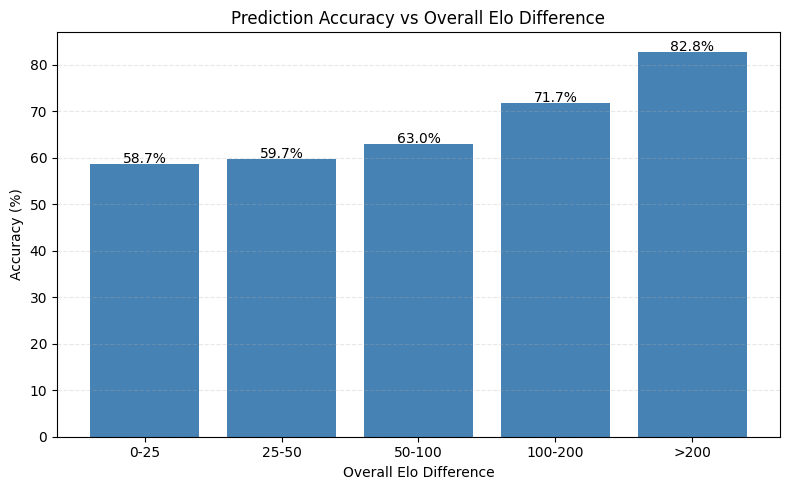

In [39]:
import matplotlib.pyplot as plt

plot_df = elo_results.copy()

# plot_df["Accuracy"] *= 100

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(plot_df["Elo Difference"], plot_df["Accuracy"], color="steelblue")

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Overall Elo Difference")
ax.set_title("Prediction Accuracy vs Overall Elo Difference")

ax.grid(axis="y", linestyle="--", alpha=0.3)

for bar, value in zip(bars, plot_df["Accuracy"]):
    ax.text(bar.get_x()+bar.get_width()/2, value+0.2, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()


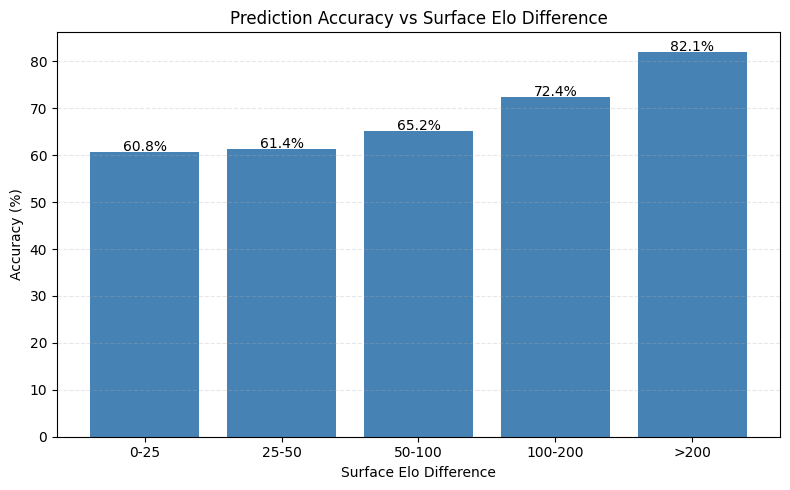

In [40]:
import matplotlib.pyplot as plt

plot_df = surface_elo_results.copy()

# plot_df["Accuracy"] *= 100

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(
    plot_df["Surface Elo Difference"],
    plot_df["Accuracy"],
    color="steelblue"
)

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Surface Elo Difference")
ax.set_title("Prediction Accuracy vs Surface Elo Difference")

ax.grid(axis="y", linestyle="--", alpha=0.3)

for bar, value in zip(bars, plot_df["Accuracy"]):
    ax.text(
        bar.get_x()+bar.get_width()/2,
        value+0.2,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


## Tournament Level

### Preparation and Data Collection

In [41]:
X_test_tourney = X_test.copy()

tourney_cols = [c for c in X_test_tourney.columns if c.startswith("tourney_level_")]

X_test_tourney['tourney_level'] = X_test_tourney[tourney_cols].idxmax(axis= 1).str.replace("tourney_level_", "", regex= False)

X_test_tourney.loc[X_test_tourney[tourney_cols].sum(axis=1).eq(0), "tourney_level"] = pd.NA


In [42]:
level_names = {
    "G": "Grand Slam",
    "M": "Masters 1000",
    "A": "ATP Tour",
    "F": "ATP Finals",
    "D": "Davis Cup",
    "C": "Challenger"
}

X_test_tourney['Tournament Level'] = X_test_tourney['tourney_level'].map(level_names)


In [43]:
X_train_val = pd.concat([X_train, X_val], axis= 0)

X_train_val['tourney_level'] = X_train_val[tourney_cols].idxmax(axis= 1).str.replace("tourney_level_", "", regex= False)

X_train_val['Tournament Level'] = X_train_val['tourney_level'].map(level_names)
X_train_val['Tournament Level'].value_counts()


,count
Tournament Level,
Challenger,91986
ATP Tour,71533
Grand Slam,21263
Masters 1000,21192
Davis Cup,1240
ATP Finals,527


### Evaluating Metrics

In [44]:
from sklearn.metrics import accuracy_score, roc_auc_score

overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100

level_results= list()
for level in X_test_tourney['Tournament Level'].dropna().unique():
    idx = X_test_tourney['Tournament Level']==level

    acc = accuracy_score(predictions_df['playerA_wins'][idx], predictions_df['playerA_wins_prediction'][idx])*100

    level_results.append({
        "Tournament Level": level,
        "Matches": idx.sum(),
        "Accuracy": acc,
        "ROC-AUC": safe_roc_auc(predictions_df['playerA_wins'][idx], predictions_df['match_win_probA'][idx]) * 100,
        "Difference in Accuracy": acc - overall_accuracy,
        "Error Rate (%)": 100 - acc
    })

level_results = pd.DataFrame(level_results).sort_values("Accuracy", ascending=False)
level_results


,Tournament Level,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
3,Grand Slam,1429,69.209237,77.077586,0.305122,30.790763
0,Challenger,20114,66.684896,73.272267,-2.219219,33.315104
1,ATP Tour,3677,66.086484,71.867454,-2.817631,33.913516
4,Davis Cup,104,64.423077,73.962963,-4.481038,35.576923
2,Masters 1000,1994,63.089268,69.395970,-5.814847,36.910732
5,ATP Finals,60,58.333333,70.000000,-10.570782,41.666667


### Plots

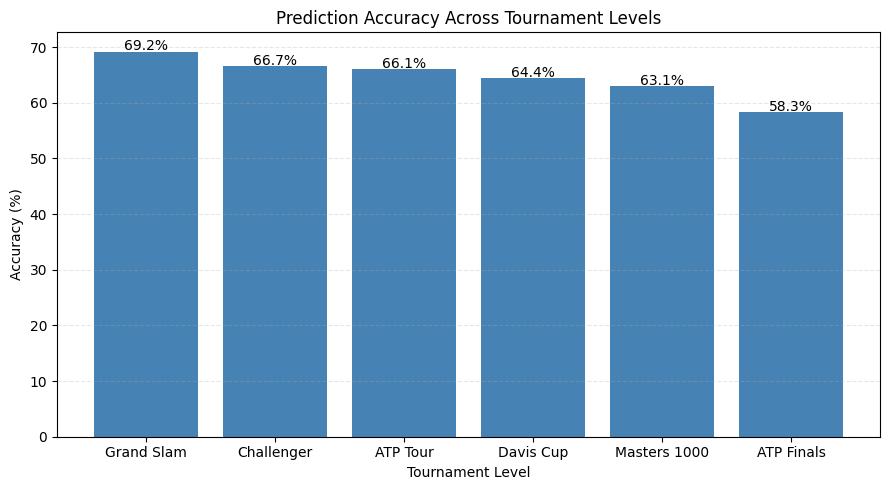

In [45]:
import matplotlib.pyplot as plt

plot_df = level_results.sort_values("Accuracy", ascending=False)

fig, ax = plt.subplots(figsize=(9,5))

bars = ax.bar(plot_df["Tournament Level"], plot_df["Accuracy"], color="steelblue")

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Tournament Level")
ax.set_title("Prediction Accuracy Across Tournament Levels")

ax.grid(axis="y", linestyle="--", alpha=0.3)

offset = 0.2

for bar, value in zip(bars, plot_df["Accuracy"]):
    ax.text(bar.get_x()+bar.get_width()/2, value+offset, f"{value:.1f}%", ha="center", fontsize=10)

plt.tight_layout()
plt.show()


## Round

### Preparation and Data Collection

In [46]:
X_test_round = X_test.copy()

round_cols = [c for c in X_test_round.columns if c.startswith("round_")]

X_test_round['Round'] = X_test_round[round_cols].idxmax(axis= 1).str.replace("round_", "", regex= False)

X_test_round.loc[X_test_round[round_cols].sum(axis=1).eq(0), "Round"] = pd.NA


In [47]:
round_names = {
    "BR": "Bronze Match",
    "ER": "Early Round",
    "F": "Final",
    "Q1": "Qualifying R1",
    "Q2": "Qualifying R2",
    "Q3": "Qualifying R3",
    "Q4": "Qualifying R4",
    "SF": "Semifinal",
    "QF": "Quarterfinal",
    "R128": "Round of 128",
    "R64": "Round of 64",
    "R32": "Round of 32",
    "R16": "Round of 16",
    "RR": "Round Robin"
}

X_test_round["Round"] = X_test_round['Round'].map(round_names)


In [48]:
X_train_val = pd.concat([X_train, X_val], axis= 0)

X_train_val['Round'] = X_train_val[round_cols].idxmax(axis= 1).str.replace("round_", "", regex= False)

X_train_val["Round"] = X_train_val['Round'].map(round_names)
X_train_val['Round'].value_counts()


,count
Round,
Round of 32,69841
Round of 16,35675
Qualifying R1,23063
Round of 64,18867
Quarterfinal,17843
Qualifying R2,12988
Round of 128,10277
Semifinal,9018
Final,4538


### Evaluating Metrics

In [49]:
from sklearn.metrics import accuracy_score, roc_auc_score

overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100

round_results = list()

for rnd in X_test_round["Round"].dropna().unique():
    idx = X_test_round["Round"]==rnd

    acc = accuracy_score(predictions_df["playerA_wins"][idx], predictions_df['playerA_wins_prediction'][idx]) * 100

    round_results.append({
        "Round": rnd,
        "Matches": idx.sum(),
        "Accuracy": acc,
        "ROC-AUC": safe_roc_auc(predictions_df["playerA_wins"][idx], predictions_df['match_win_probA'][idx]) * 100,
        "Difference in Accuracy": acc - overall_accuracy,
        "Error Rate (%)": 100 - acc
    })

round_results = pd.DataFrame(round_results).sort_values("Accuracy", ascending=False)

round_results


,Round,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
8,Bronze Match,1,100.000000,NaN,31.095885,0.000000
0,Qualifying R1,6070,71.680395,79.778402,2.776280,28.319605
2,Round of 32,20930,70.563784,77.736767,1.659669,29.436216
3,Round of 16,10465,69.966555,76.963807,1.062440,30.033445
7,Round of 64,808,66.089109,73.044386,-2.815006,33.910891
4,Quarterfinal,5190,65.818882,71.584625,-3.085232,34.181118
1,Qualifying R2,3191,64.274522,70.147316,-4.629593,35.725478
5,Semifinal,2603,63.580484,69.515736,-5.323631,36.419516
10,Round of 128,768,62.760417,69.948426,-6.143698,37.239583
9,Qualifying R3,96,62.500000,59.964727,-6.404115,37.500000


### Plots

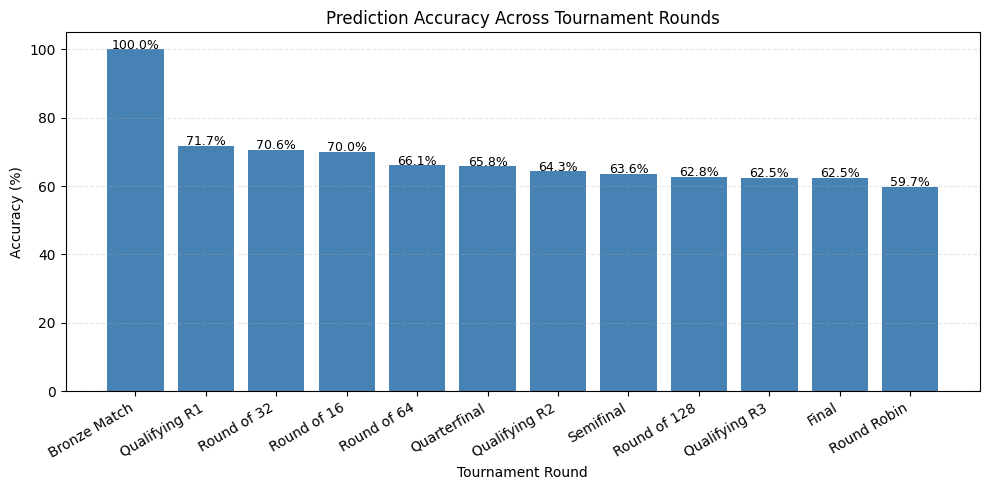

In [50]:
import matplotlib.pyplot as plt

plot_df = round_results.sort_values(
    "Accuracy",
    ascending=False
)

fig, ax = plt.subplots(figsize=(10,5))

bars = ax.bar(
    plot_df["Round"],
    plot_df["Accuracy"],
    color="steelblue"
)

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Tournament Round")
ax.set_title("Prediction Accuracy Across Tournament Rounds")

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.xticks(rotation=30, ha="right")

for bar, value in zip(bars, plot_df["Accuracy"]):

    ax.text(
        bar.get_x()+bar.get_width()/2,
        value+0.2,
        f"{value:.1f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()


## Rank Difference

### Preparation and Data Analysis

In [51]:
X_test_rank = X_test.copy()

X_test_rank['rank_diff'] = X_test_rank['rank_diff'].abs()


In [52]:
import numpy as np
import pandas as pd

rank_bins = [0, 10, 25, 50, 100, np.inf]
rank_labels = ['0-10', '10-25', '25-50', '50-100', '100+']

X_test_rank['Rank Difference'] = pd.cut(X_test_rank['rank_diff'], bins= rank_bins, labels= rank_labels, include_lowest= True)
X_test_rank['Rank Difference'].value_counts()


,count
Rank Difference,
100+,36132
50-100,6460
25-50,4127
10-25,2680
0-10,2267


In [53]:
X_train_val = pd.concat([X_train, X_val], axis= 0)

X_train_val['rank_diff'] = X_train_val['rank_diff'].abs()

X_train_val['Rank Difference'] = pd.cut(X_train_val['rank_diff'], bins= rank_bins, labels= rank_labels, include_lowest= True)
X_train_val['Rank Difference'].value_counts()


,count
Rank Difference,
100+,81724
50-100,45375
25-50,36637
10-25,25752
0-10,18253


### Evaluating Metrics

In [54]:
from sklearn.metrics import accuracy_score, roc_auc_score

overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100

rank_difference_results = list()

for group in rank_labels:
    idx = X_test_rank['Rank Difference']==group

    if idx.sum()==0:
        continue
    acc = accuracy_score(predictions_df["playerA_wins"][idx], predictions_df['playerA_wins_prediction'][idx]) * 100
    

    rank_difference_results.append({
        "Rank Difference": group, 
        "Matches": idx.sum(),
        "Accuracy": acc, 
        "ROC-AUC": safe_roc_auc(predictions_df["playerA_wins"][idx], predictions_df['match_win_probA'][idx]) * 100,
        "Difference in Accuracy": acc - overall_accuracy, 
        "Error Rate (%)": 100- acc
    })

rank_difference_results = pd.DataFrame(rank_difference_results)
rank_difference_results


,Rank Difference,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
0,0-10,2267,60.873401,66.637167,-8.030714,39.126599
1,10-25,2680,60.149254,64.698077,-8.754861,39.850746
2,25-50,4127,61.037073,66.290182,-7.867042,38.962927
3,50-100,6460,62.817337,68.098775,-6.086777,37.182663
4,100+,36132,72.044171,79.040255,3.140056,27.955829


### Plots

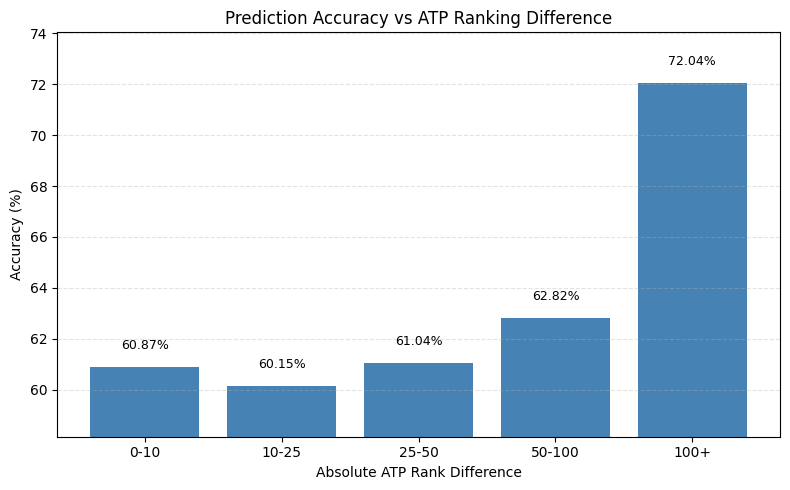

In [55]:
import matplotlib.pyplot as plt

plot_df = rank_difference_results.copy()

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(
    plot_df["Rank Difference"],
    plot_df["Accuracy"],
    color="steelblue"
)

# Dynamic y-axis
ymin = plot_df["Accuracy"].min()
ymax = plot_df["Accuracy"].max()

ax.set_ylim(ymin - 2, ymax + 2)

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Absolute ATP Rank Difference")
ax.set_title("Prediction Accuracy vs ATP Ranking Difference")

ax.grid(axis="y", linestyle="--", alpha=0.35)

# Labels
offset = (ymax - ymin) * 0.05

for bar, value in zip(bars, plot_df["Accuracy"]):

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + offset,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.show()


## Highest Ranked Player

### Preparation and Data Analysis

In [56]:
X_test_rank['Best Rank'] = np.minimum(X_test_rank['playerA_rank_filled'], X_test_rank['playerB_rank_filled'])

best_rank_bins = [0, 10, 20, 50, 100, np.inf]
best_rank_labels = ["Top 10", "11-20", "21-50", "51-100", ">100"]

X_test_rank["Highest Rank Analysis"] = pd.cut(X_test_rank["Best Rank"], bins= best_rank_bins, labels= best_rank_labels, 
                                                include_lowest= True)

X_test_rank["Highest Rank Analysis"].value_counts()


,count
Highest Rank Analysis,
>100,45107
51-100,2899
21-50,1765
Top 10,1050
11-20,845


In [57]:
X_train_val['Best Rank'] = np.minimum(X_train_val['playerA_rank_filled'], X_train_val['playerB_rank_filled'])

best_rank_bins = [0, 10, 20, 50, 100, np.inf]
best_rank_labels = ["Top 10", "11-20", "21-50", "51-100", ">100"]

X_train_val['Highest Rank Analysis'] = pd.cut(X_train_val['Best Rank'], bins= best_rank_bins, labels= best_rank_labels, 
                                                include_lowest= True)
X_train_val['Highest Rank Analysis'].value_counts()


,count
Highest Rank Analysis,
>100,104169
51-100,36820
21-50,31907
Top 10,19681
11-20,15164


### Evaluation Metrics

In [58]:
best_rank_results = []

for group in best_rank_labels:
    idx = X_test_rank["Highest Rank Analysis"] == group

    if idx.sum() == 0:
        continue

    acc = accuracy_score(predictions_df["playerA_wins"][idx], predictions_df['playerA_wins_prediction'][idx]) * 100


    best_rank_results.append({
        "Highest Ranked Player": group,
        "Matches": idx.sum(),
        "Accuracy": acc,
        "ROC-AUC": safe_roc_auc(predictions_df["playerA_wins"][idx], predictions_df['match_win_probA'][idx]) * 100,
        "Difference in Accuracy": acc - overall_accuracy,
        "Error Rate (%)":
            100 - acc
    })

best_rank_results = pd.DataFrame(best_rank_results)
best_rank_results


,Highest Ranked Player,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
0,Top 10,1050,75.619048,84.317355,6.714933,24.380952
1,11-20,845,66.627219,71.944575,-2.276896,33.372781
2,21-50,1765,63.796034,69.300849,-5.108081,36.203966
3,51-100,2899,64.160055,69.761059,-4.744060,35.839945
4,>100,45107,69.295231,76.431002,0.391116,30.704769


### Plots

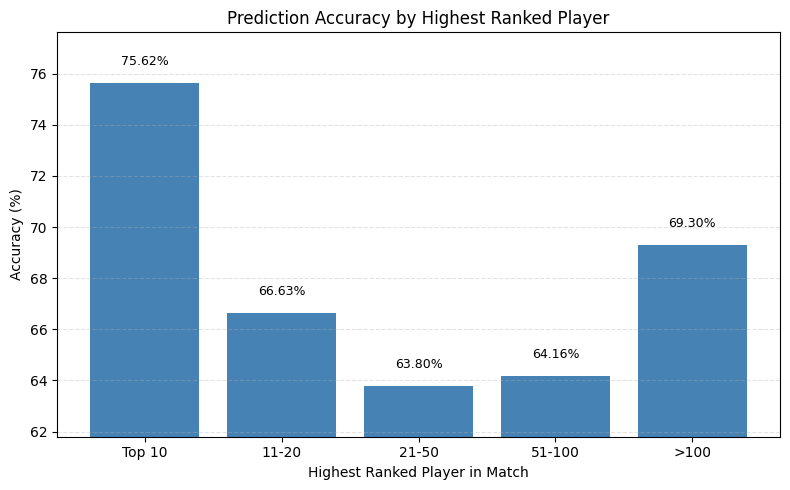

In [59]:
import matplotlib.pyplot as plt

plot_df = best_rank_results.copy()

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(
    plot_df["Highest Ranked Player"],
    plot_df["Accuracy"],
    color="steelblue"
)

ymin = plot_df["Accuracy"].min()
ymax = plot_df["Accuracy"].max()

ax.set_ylim(ymin - 2, ymax + 2)

ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Highest Ranked Player in Match")
ax.set_title("Prediction Accuracy by Highest Ranked Player")

ax.grid(axis="y", linestyle="--", alpha=0.35)

offset = (ymax - ymin) * 0.05

for bar, value in zip(bars, plot_df["Accuracy"]):

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + offset,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.show()


## Experience

### Preparation and Data Analysis

In [60]:
X_test_experience = X_test.copy()

X_test_experience['Average Experience'] = (X_test_experience['playerA_career_matches'] + 
                                                    X_test_experience['playerB_career_matches'])/2


In [61]:
experience_bins = [0,100,250,500,1000,np.inf]
experience_labels = ["0-100", "100-250", "250-500", "500-1000", ">1000"]

X_test_experience['Experience'] = pd.cut(X_test_experience['Average Experience'], bins= experience_bins, labels= experience_labels,
                                            include_lowest= True)
X_test_experience['Experience'].value_counts()


,count
Experience,
250-500,15795
100-250,15764
0-100,11918
500-1000,8098
>1000,91


In [62]:
X_train_val['Average Experience'] = (X_train_val['playerA_career_matches'] + X_train_val['playerB_career_matches'])/2

X_train_val['Experience'] = pd.cut(X_train_val['Average Experience'], bins= experience_bins, labels= experience_labels, 
                                    include_lowest= True)
X_train_val['Experience'].value_counts()


,count
Experience,
250-500,97750
500-1000,57501
100-250,40044
0-100,11796
>1000,650


### Evaluation Metrics

In [63]:
from sklearn.metrics import accuracy_score, roc_auc_score

overall_accuracy = accuracy_score(predictions_df["playerA_wins"], predictions_df['playerA_wins_prediction']) * 100

experience_results= list()

for group in experience_labels:
    idx= X_test_experience["Experience"]==group

    if idx.sum()==0:
        continue

    acc = accuracy_score(predictions_df["playerA_wins"][idx], predictions_df['playerA_wins_prediction'][idx])*100

    experience_results.append({
        "Experience": group, 
        "Matches": idx.sum(), 
        "Accuracy": acc, 
        "ROC-AUC": safe_roc_auc(predictions_df["playerA_wins"][idx], predictions_df['match_win_probA'][idx]) * 100,
        "Difference in Accuracy": acc-overall_accuracy, 
        "Error Rate (%)": 100-acc
    })

experience_results = pd.DataFrame(experience_results)
experience_results


,Experience,Matches,Accuracy,ROC-AUC,Difference in Accuracy,Error Rate (%)
0,0-100,11918,71.337473,78.596164,2.433358,28.662527
1,100-250,15764,71.105049,78.735640,2.200935,28.894951
2,250-500,15795,66.799620,73.284382,-2.104495,33.200380
3,500-1000,8098,65.065448,71.132336,-3.838667,34.934552
4,>1000,91,75.824176,81.231231,6.920061,24.175824


### Plots

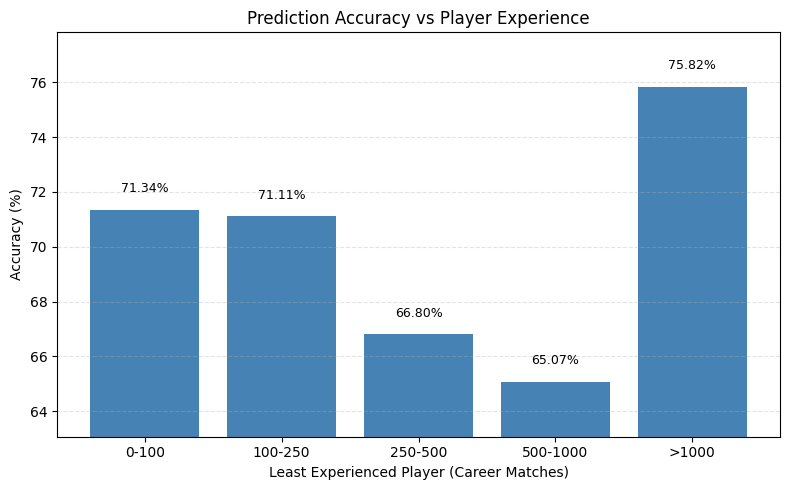

In [64]:
import matplotlib.pyplot as plt

plot_df = experience_results.copy()

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(
    plot_df["Experience"],
    plot_df["Accuracy"],
    color="steelblue"
)

# Dynamic y-axis
ymin = plot_df["Accuracy"].min()
ymax = plot_df["Accuracy"].max()

ax.set_ylim(ymin - 2, ymax + 2)

ax.set_xlabel("Least Experienced Player (Career Matches)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Prediction Accuracy vs Player Experience")

ax.grid(axis="y", linestyle="--", alpha=0.35)

# Label spacing
offset = (ymax - ymin) * 0.05

for bar, value in zip(bars, plot_df["Accuracy"]):

    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + offset,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()
